# Librerias

In [15]:
import os
import pandas as pd

from dotenv import load_dotenv
from sqlalchemy import create_engine, text, URL

load_dotenv()

url = URL.create(
    drivername="postgresql+psycopg2",
    username=os.getenv("DB_USER"),
    password=os.getenv("DB_PASSWORD"),
    host=os.getenv("DB_HOST"),
    port=int(os.getenv("DB_PORT", 5432)),
    database=os.getenv("DB_NAME")
)

engine = create_engine(url)

df = pd.read_sql(
    text("""
        SELECT *
        FROM dataset_modelo_diario
        ORDER BY fecha_objetivo, comuna
    """),
    engine
)

print(df.shape)
display(df.head())

(76840, 11)


,comuna,fecha_objetivo,temperatura_media,temperatura_max,humedad_media,humedad_min,viento_medio,viento_max,vegetacion_cobertura,incendios_historicos,ocurrencia_incendio
0,Algarrobo,2019-06-02,12.52,17.7,83.96,60.0,2.11,6.1,Bosques,13.73,0
1,Cartagena,2019-06-02,12.29,16.8,86.25,70.0,3.29,7.8,Bosques,31.35,0
2,Casablanca,2019-06-02,12.52,17.7,83.96,60.0,2.11,6.1,Bosques,28.49,0
3,Concón,2019-06-02,12.66,18.5,79.88,50.0,3.62,9.0,Bosques,12.01,0
4,El Quisco,2019-06-02,12.29,16.8,86.25,70.0,3.29,7.8,Bosques,8.93,0


In [16]:
df

,comuna,fecha_objetivo,temperatura_media,temperatura_max,humedad_media,humedad_min,viento_medio,viento_max,vegetacion_cobertura,incendios_historicos,ocurrencia_incendio
0,Algarrobo,2019-06-02,12.52,17.7,83.96,60.0,2.11,6.1,Bosques,13.73,0
1,Cartagena,2019-06-02,12.29,16.8,86.25,70.0,3.29,7.8,Bosques,31.35,0
2,Casablanca,2019-06-02,12.52,17.7,83.96,60.0,2.11,6.1,Bosques,28.49,0
3,Concón,2019-06-02,12.66,18.5,79.88,50.0,3.62,9.0,Bosques,12.01,0
4,El Quisco,2019-06-02,12.29,16.8,86.25,70.0,3.29,7.8,Bosques,8.93,0
...,...,...,...,...,...,...,...,...,...,...,...
76835,Santo Domingo,2025-05-30,8.65,17.9,86.88,59.0,3.52,10.3,Bosques,18.42,0
76836,Valparaíso,2025-05-30,13.00,20.4,68.65,46.0,2.01,9.4,Bosques,133.31,0
76837,Villa Alemana,2025-05-30,10.58,17.3,79.85,57.0,0.41,7.0,Bosques,74.84,0
76838,Viña del Mar,2025-05-30,13.00,20.4,68.65,46.0,2.01,9.4,Áreas Urbanas e Industriales,59.50,0


# Data Understanding

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76840 entries, 0 to 76839
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   comuna                76840 non-null  object 
 1   fecha_objetivo        76840 non-null  object 
 2   temperatura_media     76840 non-null  float64
 3   temperatura_max       76840 non-null  float64
 4   humedad_media         76840 non-null  float64
 5   humedad_min           76840 non-null  float64
 6   viento_medio          76840 non-null  float64
 7   viento_max            76840 non-null  float64
 8   vegetacion_cobertura  76840 non-null  object 
 9   incendios_historicos  76840 non-null  float64
 10  ocurrencia_incendio   76840 non-null  int64  
dtypes: float64(7), int64(1), object(3)
memory usage: 6.4+ MB


In [18]:
df["fecha_objetivo"] = pd.to_datetime(df["fecha_objetivo"])

print("Registros:", len(df))
print("Comunas:", df["comuna"].nunique())
print("Periodo:", df["fecha_objetivo"].min(), "a", df["fecha_objetivo"].max())
print("Duplicados comuna-fecha:", df.duplicated(["comuna", "fecha_objetivo"]).sum())

Registros: 76840
Comunas: 36
Periodo: 2019-06-02 00:00:00 a 2025-05-30 00:00:00
Duplicados comuna-fecha: 0


In [19]:
print(df["ocurrencia_incendio"].value_counts())

print(
    df["ocurrencia_incendio"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

ocurrencia_incendio
0    74520
1     2320
Name: count, dtype: int64
ocurrencia_incendio
0    96.98
1     3.02
Name: proportion, dtype: float64


In [20]:
print(df["vegetacion_cobertura"].value_counts())

vegetacion_cobertura
Bosques                             54113
Terrenos Agrícolas                   8484
Praderas y Matorrales                6336
Áreas Desprovistas de Vegetación     6336
Áreas Urbanas e Industriales         1571
Name: count, dtype: int64


In [21]:
columnas_numericas = [
    "temperatura_media",
    "temperatura_max",
    "humedad_media",
    "humedad_min",
    "viento_medio",
    "viento_max",
    "incendios_historicos"
]

display(df[columnas_numericas].describe().round(2))

,temperatura_media,temperatura_max,humedad_media,humedad_min,viento_medio,viento_max,incendios_historicos
count,76840.00,76840.00,76840.00,76840.00,76840.00,76840.00,76840.00
mean,14.31,21.53,71.71,45.48,3.04,9.49,22.38
std,4.14,6.28,15.18,20.59,1.81,4.23,31.42
min,3.04,7.30,24.21,3.00,0.00,0.00,0.23
25%,11.31,16.80,60.04,27.00,1.64,6.20,3.89
50%,13.94,20.10,74.26,46.00,2.61,8.70,11.10
75%,16.81,26.00,83.63,62.00,4.30,12.40,28.49
max,26.72,37.90,100.00,100.00,13.37,30.50,133.31


In [22]:
print("Humedad mínima = 0:", (df["humedad_min"] == 0).sum())
print("Viento máximo = 0:", (df["viento_max"] == 0).sum())

display(
    df[df["humedad_min"] == 0][
        ["comuna", "fecha_objetivo", "humedad_media", "humedad_min"]
    ].head(10)
)

Humedad mínima = 0: 0
Viento máximo = 0: 13


,comuna,fecha_objetivo,humedad_media,humedad_min


In [23]:
ceros_humedad = df[df["humedad_min"] == 0]

print("Filas con humedad_min = 0:", len(ceros_humedad))
print("Fechas afectadas:", ceros_humedad["fecha_objetivo"].nunique())
print("Comunas afectadas:", ceros_humedad["comuna"].nunique())

display(
    ceros_humedad.groupby("fecha_objetivo")
    .size()
    .sort_values(ascending=False)
    .head(20)
)

Filas con humedad_min = 0: 0
Fechas afectadas: 0
Comunas afectadas: 0


Series([], dtype: int64)

In [24]:
display(
    ceros_humedad[
        ["fecha_objetivo", "humedad_media", "humedad_min"]
    ]
    .drop_duplicates()
    .sort_values("fecha_objetivo")
    .head(30)
)

,fecha_objetivo,humedad_media,humedad_min


In [25]:
print("Humedad mínima = 0:", (df["humedad_min"] == 0).sum())

Humedad mínima = 0: 0


# Data Preparation

In [26]:
df["fecha_objetivo"] = pd.to_datetime(df["fecha_objetivo"])

train = df[df["fecha_objetivo"] < "2024-01-01"].copy()

val = df[
    (df["fecha_objetivo"] >= "2024-01-01") &
    (df["fecha_objetivo"] < "2025-01-01")
].copy()

test = df[df["fecha_objetivo"] >= "2025-01-01"].copy()

print("Train:", train.shape,
      train["fecha_objetivo"].min(), "a",
      train["fecha_objetivo"].max())

print("Validación:", val.shape,
      val["fecha_objetivo"].min(), "a",
      val["fecha_objetivo"].max())

print("Test:", test.shape,
      test["fecha_objetivo"].min(), "a",
      test["fecha_objetivo"].max())

Train: (59366, 11) 2019-06-02 00:00:00 a 2023-12-31 00:00:00
Validación: (12109, 11) 2024-01-01 00:00:00 a 2024-12-31 00:00:00
Test: (5365, 11) 2025-01-01 00:00:00 a 2025-05-30 00:00:00


In [27]:
for nombre, datos in [
    ("Train", train),
    ("Validación", val),
    ("Test", test)
]:
    print(
        nombre,
        datos["ocurrencia_incendio"].value_counts().to_dict(),
        "Positivos:",
        round(datos["ocurrencia_incendio"].mean() * 100, 2),
        "%"
    )

Train {0: 57734, 1: 1632} Positivos: 2.75 %
Validación {0: 11666, 1: 443} Positivos: 3.66 %
Test {0: 5120, 1: 245} Positivos: 4.57 %


In [31]:
# Target
target = "ocurrencia_incendio"

# Experimento A: variables meteorológicas medias
features_a = [
    "temperatura_media",
    "humedad_media",
    "viento_medio",
    "vegetacion_cobertura",
    "incendios_historicos"
]

# Experimento B: variables meteorológicas extremas
features_b = [
    "temperatura_max",
    "humedad_min",
    "viento_max",
    "vegetacion_cobertura",
    "incendios_historicos"
]

# Variables por tipo
categoricas = ["vegetacion_cobertura"]

numericas_a = [
    "temperatura_media",
    "humedad_media",
    "viento_medio",
    "incendios_historicos"
]

numericas_b = [
    "temperatura_max",
    "humedad_min",
    "viento_max",
    "incendios_historicos"
]

In [32]:
# Target
y_train = train[target]
y_val = val[target]
y_test = test[target]

# Experimento A: medias
X_train_a = train[features_a]
X_val_a = val[features_a]
X_test_a = test[features_a]

# Experimento B: extremos
X_train_b = train[features_b]
X_val_b = val[features_b]
X_test_b = test[features_b]

print("Experimento A")
print("Train:", X_train_a.shape)
print("Validación:", X_val_a.shape)
print("Test:", X_test_a.shape)

print("\nExperimento B")
print("Train:", X_train_b.shape)
print("Validación:", X_val_b.shape)
print("Test:", X_test_b.shape)

Experimento A
Train: (59366, 5)
Validación: (12109, 5)
Test: (5365, 5)

Experimento B
Train: (59366, 5)
Validación: (12109, 5)
Test: (5365, 5)


In [33]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [34]:
preprocesador_logistico_a = ColumnTransformer([
    ("num", StandardScaler(), numericas_a),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas)
])

preprocesador_logistico_b = ColumnTransformer([
    ("num", StandardScaler(), numericas_b),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas)
])

In [35]:
preprocesador_arboles_a = ColumnTransformer([
    ("num", "passthrough", numericas_a),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas)
])

preprocesador_arboles_b = ColumnTransformer([
    ("num", "passthrough", numericas_b),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas)
])

# Entrenamiento de modelos

In [36]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

In [37]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


# Calcular el desbalance para XGBoost

In [38]:
negativos = (y_train == 0).sum()
positivos = (y_train == 1).sum()

scale_pos_weight = negativos / positivos

print("Negativos:", negativos)
print("Positivos:", positivos)
print("scale_pos_weight:", round(scale_pos_weight, 2))

Negativos: 57734
Positivos: 1632
scale_pos_weight: 35.38


In [43]:
import numpy as np
from sklearn.model_selection import PredefinedSplit, GridSearchCV

# Train + Validación para búsqueda de hiperparámetros
train_val = pd.concat([train, val], ignore_index=True)

X_train_val_a = train_val[features_a]
X_train_val_b = train_val[features_b]
y_train_val = train_val[target]

# -1 = entrenamiento (2019-2023)
#  0 = validación (2024)
test_fold = np.concatenate([
    np.full(len(train), -1),
    np.zeros(len(val), dtype=int)
])

split_temporal = PredefinedSplit(test_fold)

# Regresión Logística

In [44]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

logistica_a = Pipeline([
    ("preprocesador", preprocesador_logistico_a),
    ("modelo", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

logistica_b = Pipeline([
    ("preprocesador", preprocesador_logistico_b),
    ("modelo", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

param_grid_logistica = {
    "modelo__C": [0.1, 1, 10],
    "modelo__solver": ["liblinear", "lbfgs"]
}

grid_logistica_a = GridSearchCV(
    logistica_a,
    param_grid_logistica,
    cv=split_temporal,
    scoring="average_precision",
    n_jobs=-1,
    refit=False
)

grid_logistica_b = GridSearchCV(
    logistica_b,
    param_grid_logistica,
    cv=split_temporal,
    scoring="average_precision",
    n_jobs=-1,
    refit=False
)

grid_logistica_a.fit(X_train_val_a, y_train_val)
grid_logistica_b.fit(X_train_val_b, y_train_val)

print("Regresión Logística A")
print("Mejores parámetros:", grid_logistica_a.best_params_)
print("PR-AUC validación:", round(grid_logistica_a.best_score_, 4))

print("\nRegresión Logística B")
print("Mejores parámetros:", grid_logistica_b.best_params_)
print("PR-AUC validación:", round(grid_logistica_b.best_score_, 4))

Regresión Logística A
Mejores parámetros: {'modelo__C': 0.1, 'modelo__solver': 'lbfgs'}
PR-AUC validación: 0.1034

Regresión Logística B
Mejores parámetros: {'modelo__C': 0.1, 'modelo__solver': 'lbfgs'}
PR-AUC validación: 0.1029


# Random Forest

In [45]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

random_forest_a = Pipeline([
    ("preprocesador", preprocesador_arboles_a),
    ("modelo", RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_b = Pipeline([
    ("preprocesador", preprocesador_arboles_b),
    ("modelo", RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

param_grid_rf = {
    "modelo__n_estimators": [200, 300],
    "modelo__max_depth": [8, 12, None],
    "modelo__min_samples_leaf": [2, 5, 10]
}

grid_rf_a = GridSearchCV(
    random_forest_a,
    param_grid_rf,
    cv=split_temporal,
    scoring="average_precision",
    n_jobs=-1,
    refit=False
)

grid_rf_b = GridSearchCV(
    random_forest_b,
    param_grid_rf,
    cv=split_temporal,
    scoring="average_precision",
    n_jobs=-1,
    refit=False
)

grid_rf_a.fit(X_train_val_a, y_train_val)
grid_rf_b.fit(X_train_val_b, y_train_val)

print("Random Forest A")
print("Mejores parámetros:", grid_rf_a.best_params_)
print("PR-AUC validación:", round(grid_rf_a.best_score_, 4))

print("\nRandom Forest B")
print("Mejores parámetros:", grid_rf_b.best_params_)
print("PR-AUC validación:", round(grid_rf_b.best_score_, 4))

Random Forest A
Mejores parámetros: {'modelo__max_depth': 12, 'modelo__min_samples_leaf': 5, 'modelo__n_estimators': 300}
PR-AUC validación: 0.1523

Random Forest B
Mejores parámetros: {'modelo__max_depth': 12, 'modelo__min_samples_leaf': 2, 'modelo__n_estimators': 200}
PR-AUC validación: 0.1489


# XGBoost

In [46]:
from xgboost import XGBClassifier

xgboost_a = Pipeline([
    ("preprocesador", preprocesador_arboles_a),
    ("modelo", XGBClassifier(
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        tree_method="hist",
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1
    ))
])

xgboost_b = Pipeline([
    ("preprocesador", preprocesador_arboles_b),
    ("modelo", XGBClassifier(
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        tree_method="hist",
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1
    ))
])

param_grid_xgb = {
    "modelo__n_estimators": [200, 300],
    "modelo__max_depth": [4, 6],
    "modelo__learning_rate": [0.05, 0.1],
    "modelo__subsample": [0.8, 1.0]
}

grid_xgb_a = GridSearchCV(
    xgboost_a,
    param_grid_xgb,
    cv=split_temporal,
    scoring="average_precision",
    n_jobs=-1,
    refit=False
)

grid_xgb_b = GridSearchCV(
    xgboost_b,
    param_grid_xgb,
    cv=split_temporal,
    scoring="average_precision",
    n_jobs=-1,
    refit=False
)

grid_xgb_a.fit(X_train_val_a, y_train_val)
grid_xgb_b.fit(X_train_val_b, y_train_val)

print("XGBoost A")
print("Mejores parámetros:", grid_xgb_a.best_params_)
print("PR-AUC validación:", round(grid_xgb_a.best_score_, 4))

print("\nXGBoost B")
print("Mejores parámetros:", grid_xgb_b.best_params_)
print("PR-AUC validación:", round(grid_xgb_b.best_score_, 4))

XGBoost A
Mejores parámetros: {'modelo__learning_rate': 0.05, 'modelo__max_depth': 6, 'modelo__n_estimators': 300, 'modelo__subsample': 0.8}
PR-AUC validación: 0.1498

XGBoost B
Mejores parámetros: {'modelo__learning_rate': 0.05, 'modelo__max_depth': 6, 'modelo__n_estimators': 200, 'modelo__subsample': 0.8}
PR-AUC validación: 0.1367


# Evaluación de modelos

In [47]:
from sklearn.base import clone

modelo_logistica = clone(logistica_a)
modelo_logistica.set_params(**grid_logistica_a.best_params_)

modelo_rf = clone(random_forest_a)
modelo_rf.set_params(**grid_rf_a.best_params_)

modelo_xgb = clone(xgboost_a)
modelo_xgb.set_params(**grid_xgb_a.best_params_)

modelo_logistica.fit(X_train_a, y_train)
modelo_rf.fit(X_train_a, y_train)
modelo_xgb.fit(X_train_a, y_train)

print("Modelos entrenados con sus mejores hiperparámetros.")

Modelos entrenados con sus mejores hiperparámetros.


## Métricas

In [48]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)

modelos = {
    "Regresión Logística": modelo_logistica,
    "Random Forest": modelo_rf,
    "XGBoost": modelo_xgb
}

resultados = []

for nombre, modelo in modelos.items():
    pred = modelo.predict(X_val_a)
    prob = modelo.predict_proba(X_val_a)[:, 1]

    resultados.append({
        "Modelo": nombre,
        "Precision": precision_score(y_val, pred),
        "Recall": recall_score(y_val, pred),
        "F1": f1_score(y_val, pred),
        "PR-AUC": average_precision_score(y_val, prob),
        "ROC-AUC": roc_auc_score(y_val, prob)
    })

resultados_df = pd.DataFrame(resultados)
display(resultados_df.round(4))

,Modelo,Precision,Recall,F1,PR-AUC,ROC-AUC
0,Regresión Logística,0.0779,0.7901,0.1418,0.1034,0.7706
1,Random Forest,0.1124,0.6501,0.1916,0.1523,0.8100
2,XGBoost,0.1079,0.6321,0.1844,0.1514,0.8112


## Matrices de Confusión

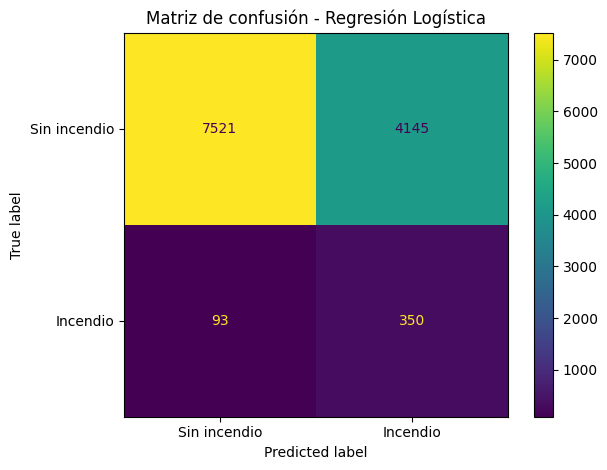

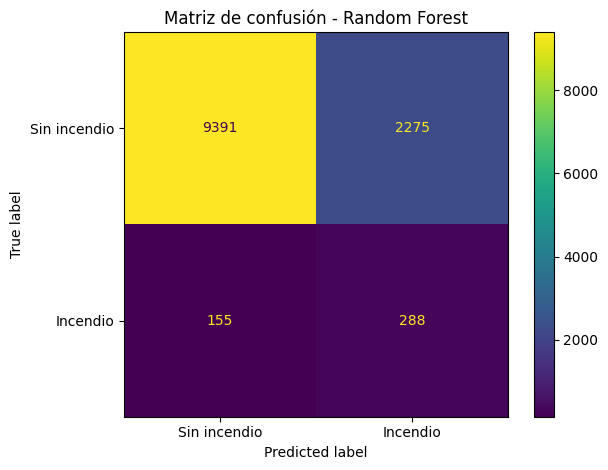

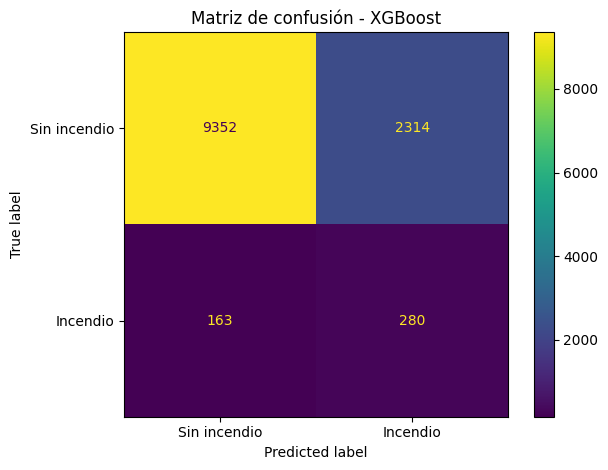

In [51]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

for nombre, modelo in modelos.items():
    pred = modelo.predict(X_val_a)

    ConfusionMatrixDisplay.from_predictions(
        y_val,
        pred,
        display_labels=["Sin incendio", "Incendio"],
        values_format="d"
    )

    plt.title(f"Matriz de confusión - {nombre}")
    plt.tight_layout()
    plt.show()

## Curvas ROC

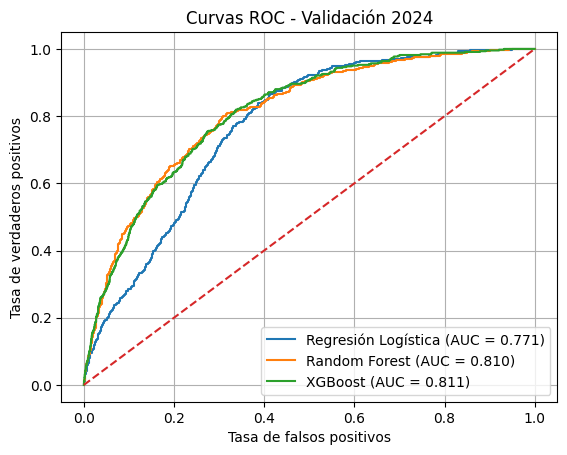

In [52]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

for nombre, modelo in modelos.items():
    prob = modelo.predict_proba(X_val_a)[:, 1]

    fpr, tpr, _ = roc_curve(y_val, prob)
    auc = roc_auc_score(y_val, prob)

    plt.plot(fpr, tpr, label=f"{nombre} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curvas ROC - Validación 2024")
plt.legend()
plt.grid()
plt.show()

## Tratamiento adicional del desbalance: undersampling

In [53]:
%pip install imbalanced-learn

   ---------------------------------------- 0.0/236.1 kB ? eta -:--:--
   ---------------------------------------- 236.1/236.1 kB 7.1 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [54]:
from imblearn.under_sampling import RandomUnderSampler

In [55]:
undersampler = RandomUnderSampler(
    sampling_strategy=0.25,  # positivos / negativos = 1/4
    random_state=42
)

X_train_under, y_train_under = undersampler.fit_resample(
    X_train_a,
    y_train
)

print("Antes:")
print(y_train.value_counts())

print("\nDespués:")
print(y_train_under.value_counts())

print("\nProporciones:")
print(y_train_under.value_counts(normalize=True).round(3))

Antes:
ocurrencia_incendio
0    57734
1     1632
Name: count, dtype: int64

Después:
ocurrencia_incendio
0    6528
1    1632
Name: count, dtype: int64

Proporciones:
ocurrencia_incendio
0    0.8
1    0.2
Name: proportion, dtype: float64


In [56]:
# Regresión Logística
logistica_under = Pipeline([
    ("preprocesador", preprocesador_logistico_a),
    ("modelo", LogisticRegression(
        C=0.1,
        solver="lbfgs",
        max_iter=2000,
        random_state=42
    ))
])

# Random Forest
random_forest_under = Pipeline([
    ("preprocesador", preprocesador_arboles_a),
    ("modelo", RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

# XGBoost
xgboost_under = Pipeline([
    ("preprocesador", preprocesador_arboles_a),
    ("modelo", XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    ))
])

logistica_under.fit(X_train_under, y_train_under)
random_forest_under.fit(X_train_under, y_train_under)
xgboost_under.fit(X_train_under, y_train_under)

print("Modelos con undersampling entrenados.")

Modelos con undersampling entrenados.


In [57]:
modelos_under = {
    "Regresión Logística": logistica_under,
    "Random Forest": random_forest_under,
    "XGBoost": xgboost_under
}

resultados_under = []

for nombre, modelo in modelos_under.items():
    pred = modelo.predict(X_val_a)
    prob = modelo.predict_proba(X_val_a)[:, 1]

    resultados_under.append({
        "Modelo": nombre,
        "Precision": precision_score(y_val, pred),
        "Recall": recall_score(y_val, pred),
        "F1": f1_score(y_val, pred),
        "PR-AUC": average_precision_score(y_val, prob),
        "ROC-AUC": roc_auc_score(y_val, prob)
    })

resultados_under_df = pd.DataFrame(resultados_under)

display(resultados_under_df.round(4))

,Modelo,Precision,Recall,F1,PR-AUC,ROC-AUC
0,Regresión Logística,0.1442,0.1738,0.1576,0.1044,0.7708
1,Random Forest,0.1701,0.3205,0.2222,0.1365,0.8023
2,XGBoost,0.1515,0.3002,0.2014,0.1314,0.7988


In [58]:
resultados_originales = pd.DataFrame({
    "Modelo": [
        "Regresión Logística",
        "Random Forest",
        "XGBoost"
    ],
    "Precision_original": [0.0779, 0.1124, 0.1079],
    "Recall_original": [0.7901, 0.6501, 0.6321],
    "F1_original": [0.1418, 0.1916, 0.1844],
    "PR_AUC_original": [0.1034, 0.1523, 0.1514]
})

comparacion = resultados_originales.merge(
    resultados_under_df,
    on="Modelo"
)

display(comparacion.round(4))

,Modelo,Precision_original,Recall_original,F1_original,PR_AUC_original,Precision,Recall,F1,PR-AUC,ROC-AUC
0,Regresión Logística,0.0779,0.7901,0.1418,0.1034,0.1442,0.1738,0.1576,0.1044,0.7708
1,Random Forest,0.1124,0.6501,0.1916,0.1523,0.1701,0.3205,0.2222,0.1365,0.8023
2,XGBoost,0.1079,0.6321,0.1844,0.1514,0.1515,0.3002,0.2014,0.1314,0.7988


## Ajuste del umbral de decisión

In [59]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Probabilidades del Random Forest en validación 2024
prob_val_rf = modelo_rf.predict_proba(X_val_a)[:, 1]

umbrales = np.arange(0.10, 0.81, 0.05)

resultados_umbral = []

for umbral in umbrales:
    pred = (prob_val_rf >= umbral).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()

    resultados_umbral.append({
        "Umbral": round(umbral, 2),
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred),
        "F1": f1_score(y_val, pred),
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

umbrales_df = pd.DataFrame(resultados_umbral)

display(umbrales_df.round(4))

,Umbral,Precision,Recall,F1,FP,FN,TP
0,0.10,0.0539,0.9458,0.1020,7356,24,419
1,0.15,0.0621,0.9165,0.1163,6131,37,406
2,0.20,0.0680,0.8736,0.1262,5301,56,387
3,0.25,0.0736,0.8465,0.1355,4718,68,375
4,0.30,0.0793,0.8239,0.1447,4237,78,365
5,0.35,0.0877,0.8081,0.1583,3723,85,358
6,0.40,0.0927,0.7494,0.1650,3250,111,332
7,0.45,0.1017,0.7020,0.1776,2748,132,311
8,0.50,0.1124,0.6501,0.1916,2275,155,288
9,0.55,0.1245,0.5982,0.2061,1864,178,265


In [60]:
mejor_fila = umbrales_df.loc[
    umbrales_df["F1"].idxmax()
]

print("Mejor umbral según F1:")
display(mejor_fila.to_frame().T.round(4))

Mejor umbral según F1:


,Umbral,Precision,Recall,F1,FP,FN,TP
12,0.7,0.1658,0.4357,0.2402,971.0,250.0,193.0


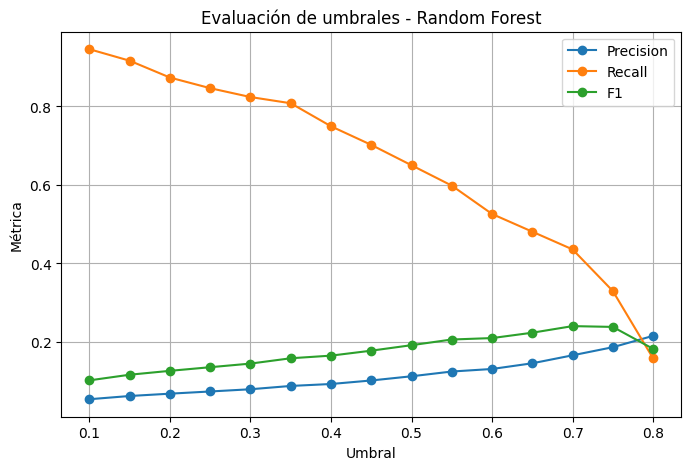

In [61]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    umbrales_df["Umbral"],
    umbrales_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    umbrales_df["Umbral"],
    umbrales_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    umbrales_df["Umbral"],
    umbrales_df["F1"],
    marker="o",
    label="F1"
)

plt.xlabel("Umbral")
plt.ylabel("Métrica")
plt.title("Evaluación de umbrales - Random Forest")
plt.legend()
plt.grid()
plt.show()

In [62]:
candidatos = umbrales_df[
    umbrales_df["Recall"] >= 0.60
].sort_values(
    "F1",
    ascending=False
)

display(candidatos.round(4))

,Umbral,Precision,Recall,F1,FP,FN,TP
8,0.50,0.1124,0.6501,0.1916,2275,155,288
7,0.45,0.1017,0.7020,0.1776,2748,132,311
6,0.40,0.0927,0.7494,0.1650,3250,111,332
5,0.35,0.0877,0.8081,0.1583,3723,85,358
4,0.30,0.0793,0.8239,0.1447,4237,78,365
3,0.25,0.0736,0.8465,0.1355,4718,68,375
2,0.20,0.0680,0.8736,0.1262,5301,56,387
1,0.15,0.0621,0.9165,0.1163,6131,37,406
0,0.10,0.0539,0.9458,0.1020,7356,24,419


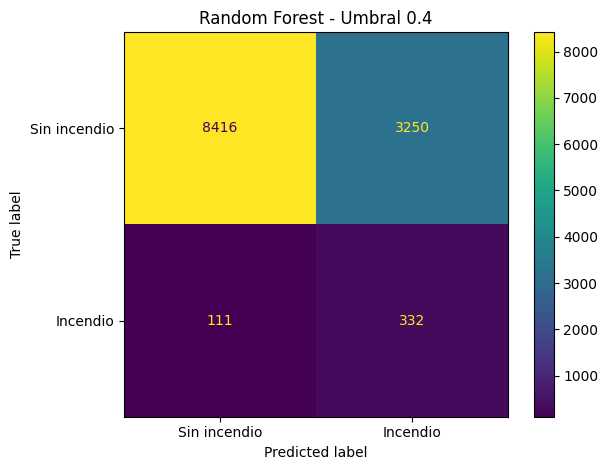

In [63]:
umbral_final = 0.40

pred_umbral = (
    prob_val_rf >= umbral_final
).astype(int)

from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_val,
    pred_umbral,
    display_labels=["Sin incendio", "Incendio"],
    values_format="d"
)

plt.title(
    f"Random Forest - Umbral {umbral_final}"
)

plt.tight_layout()
plt.show()

# TEST

In [64]:
# Datos disponibles antes del Test
train_final = pd.concat([train, val], ignore_index=True)

X_train_final = train_final[features_a]
y_train_final = train_final[target]

modelo_final = Pipeline([
    ("preprocesador", preprocesador_arboles_a),
    ("modelo", RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

modelo_final.fit(X_train_final, y_train_final)

print("Modelo final entrenado.")

Modelo final entrenado.


In [65]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)

prob_test = modelo_final.predict_proba(X_test_a)[:, 1]

umbral_final = 0.50
pred_test = (prob_test >= umbral_final).astype(int)

print("Precision:", round(precision_score(y_test, pred_test), 4))
print("Recall:", round(recall_score(y_test, pred_test), 4))
print("F1:", round(f1_score(y_test, pred_test), 4))
print("PR-AUC:", round(average_precision_score(y_test, prob_test), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, prob_test), 4))

Precision: 0.0917
Recall: 0.5878
F1: 0.1587
PR-AUC: 0.112
ROC-AUC: 0.7185


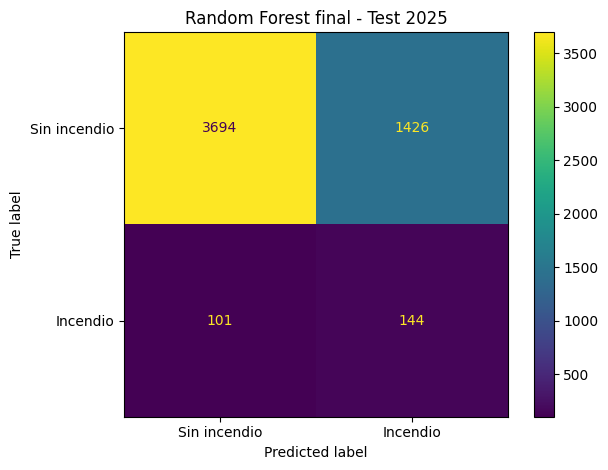

In [66]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_test,
    display_labels=["Sin incendio", "Incendio"],
    values_format="d"
)

plt.title("Random Forest final - Test 2025")
plt.tight_layout()
plt.show()

# Guardado del modelo final

In [67]:
import joblib
from pathlib import Path

MODELS_DIR = Path("models")
MODELS_DIR.mkdir(exist_ok=True)

joblib.dump(
    modelo_final,
    MODELS_DIR / "random_forest_incendios.joblib"
)

print("Modelo guardado correctamente.")

Modelo guardado correctamente.


# Prueba modelo

In [68]:
import joblib
import pandas as pd

modelo = joblib.load("models/random_forest_incendios.joblib")

ejemplo = pd.DataFrame([{
    "temperatura_media": 25.0,
    "humedad_media": 40.0,
    "viento_medio": 6.0,
    "vegetacion_cobertura": "Bosques",
    "incendios_historicos": 30.0
}])

probabilidad = modelo.predict_proba(ejemplo)[0, 1]
prediccion = int(probabilidad >= 0.50)

print("Probabilidad:", round(probabilidad, 4))
print("Predicción:", prediccion)

Probabilidad: 0.6588
Predicción: 1


In [69]:
indice = y_test[y_test == 1].index[0]

ejemplo = X_test_a.loc[[indice]]
clase_real = y_test.loc[indice]

probabilidad = modelo.predict_proba(ejemplo)[0, 1]
prediccion = int(probabilidad >= 0.50)

display(ejemplo)

print("Probabilidad:", round(probabilidad, 4))
print("Predicción:", prediccion)
print("Clase real:", clase_real)

,temperatura_media,humedad_media,viento_medio,vegetacion_cobertura,incendios_historicos
71483,15.55,84.55,6.6,Bosques,12.01


Probabilidad: 0.2794
Predicción: 0
Clase real: 1


In [71]:
import joblib

modelo = joblib.load("models/random_forest_incendios.joblib")

indice = y_test[y_test == 1].index[0]

ejemplo = X_test_a.loc[[indice]]
clase_real = y_test.loc[indice]

probabilidad = modelo.predict_proba(ejemplo)[0, 1]
prediccion = int(probabilidad >= 0.50)

if probabilidad < 0.35:
    nivel_riesgo = "Bajo"
elif probabilidad < 0.50:
    nivel_riesgo = "Medio"
else:
    nivel_riesgo = "Alto"

display(ejemplo)

print("Probabilidad:", round(probabilidad, 4))
print("Nivel de riesgo:", nivel_riesgo)
print("Predicción:", prediccion)
print("Clase real:", clase_real)

,temperatura_media,humedad_media,viento_medio,vegetacion_cobertura,incendios_historicos
71483,15.55,84.55,6.6,Bosques,12.01


Probabilidad: 0.2794
Nivel de riesgo: Bajo
Predicción: 0
Clase real: 1


In [80]:
import joblib

modelo = joblib.load("models/random_forest_incendios.joblib")

# Elegir un registro aleatorio del Test 2025
indice = X_test_a.sample(n=1).index[0]

ejemplo = X_test_a.loc[[indice]]
clase_real = int(y_test.loc[indice])

# Predicción
probabilidad = modelo.predict_proba(ejemplo)[0, 1]
prediccion = int(probabilidad >= 0.50)

# Nivel de riesgo
if probabilidad < 0.35:
    nivel_riesgo = "Bajo"
elif probabilidad < 0.50:
    nivel_riesgo = "Medio"
else:
    nivel_riesgo = "Alto"

# Tipo de resultado
if prediccion == 1 and clase_real == 1:
    resultado = "Verdadero positivo"
elif prediccion == 0 and clase_real == 0:
    resultado = "Verdadero negativo"
elif prediccion == 1 and clase_real == 0:
    resultado = "Falso positivo"
else:
    resultado = "Falso negativo"

# Contexto real del registro
print("Comuna:", test.loc[indice, "comuna"])
print("Fecha:", test.loc[indice, "fecha_objetivo"])

display(ejemplo)

print("Score del modelo:", round(probabilidad, 4))
print("Nivel de riesgo:", nivel_riesgo)
print("Predicción:", prediccion)
print("Clase real:", clase_real)
print("Resultado:", resultado)

Comuna: Panquehue
Fecha: 2025-03-16 00:00:00


,temperatura_media,humedad_media,viento_medio,vegetacion_cobertura,incendios_historicos
74127,17.35,76.59,2.39,Terrenos Agrícolas,1.83


Score del modelo: 0.2713
Nivel de riesgo: Bajo
Predicción: 0
Clase real: 0
Resultado: Verdadero negativo
